In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

churn = pd.read_csv("../data/processed/churn_cleaned.csv")
findex = pd.read_csv("../data/processed/global_findex_cleaned.csv")
mobile = pd.read_csv("../data/processed/mobile_money_cleaned.csv")

print("All cleaned datasets loaded successfully!")

print("\nChurn:", churn.shape)
print("Global Findex:", findex.shape)
print("Mobile Money:", mobile.shape)


All cleaned datasets loaded successfully!

Churn: (10000, 11)
Global Findex: (8577, 12)
Mobile Money: (90, 3)


Churn Analysis

In [2]:

print("Customer churn distribution:")
print(churn["Exited"].value_counts())

print("\nChurn percentage:")
print((churn["Exited"].value_counts(normalize=True) * 100).round(2))


Customer churn distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64

Churn percentage:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


In [3]:

total_customers = len(churn)
churned_customers = churn["Exited"].sum()
retained_customers = total_customers - churned_customers

churn_rate = (churned_customers / total_customers) * 100
retention_rate = (retained_customers / total_customers) * 100

print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print("Retained customers:", retained_customers)
print("Churn rate:", round(churn_rate, 2), "%")
print("Retention rate:", round(retention_rate, 2), "%")


Total customers: 10000
Churned customers: 2037
Retained customers: 7963
Churn rate: 20.37 %
Retention rate: 79.63 %


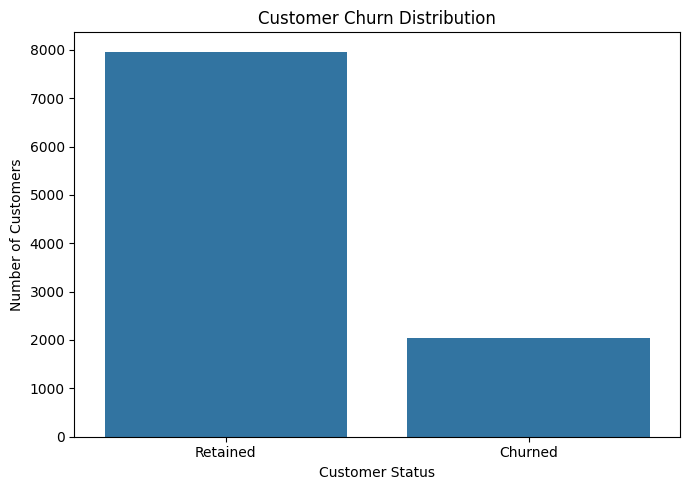

In [4]:

churn_counts = churn["Exited"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=["Retained", "Churned"],
    y=churn_counts.values
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


,Geography,Churn Rate
0,France,16.154767
1,Germany,32.443204
2,Spain,16.673395


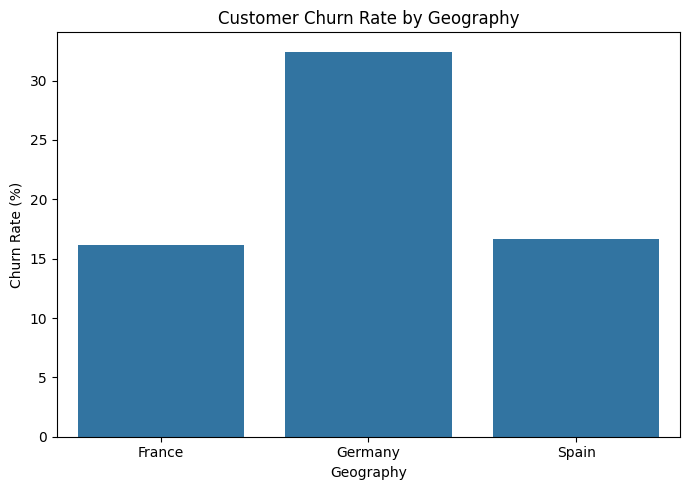

In [5]:

geography_churn = (
    churn.groupby("Geography")["Exited"]
    .mean()
    .mul(100)
    .reset_index(name="Churn Rate")
)

display(geography_churn)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=geography_churn,
    x="Geography",
    y="Churn Rate"
)

plt.title("Customer Churn Rate by Geography")
plt.xlabel("Geography")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


,Gender,Churn Rate
0,Female,25.071539
1,Male,16.455928


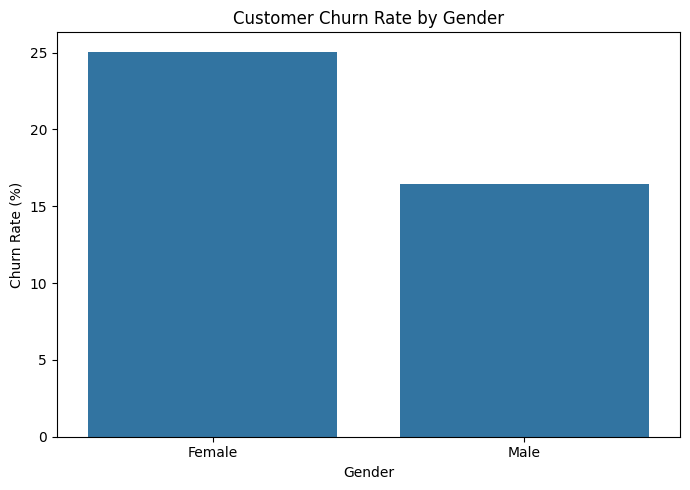

In [6]:

gender_churn = (
    churn.groupby("Gender")["Exited"]
    .mean()
    .mul(100)
    .reset_index(name="Churn Rate")
)

display(gender_churn)

plt.figure(figsize=(7, 5))
sns.barplot(data=gender_churn, x="Gender", y="Churn Rate")

plt.title("Customer Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


,Gender,Churn Rate
0,Female,25.071539
1,Male,16.455928


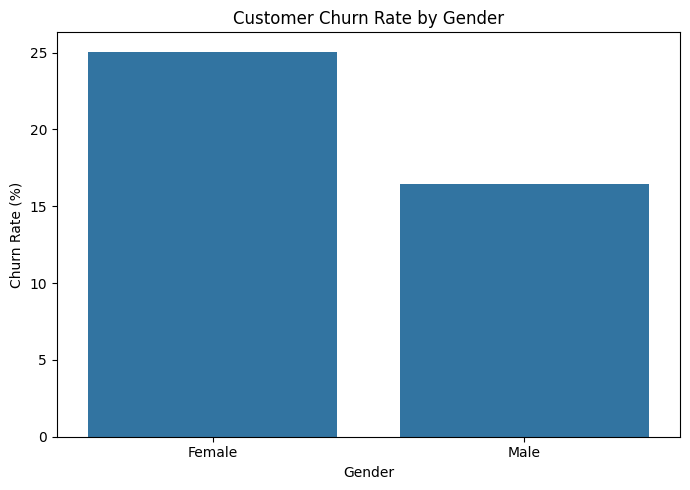

In [7]:

gender_churn = (
    churn.groupby("Gender")["Exited"]
    .mean()
    .mul(100)
    .reset_index(name="Churn Rate")
)

display(gender_churn)

plt.figure(figsize=(7, 5))
sns.barplot(data=gender_churn, x="Gender", y="Churn Rate")

plt.title("Customer Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


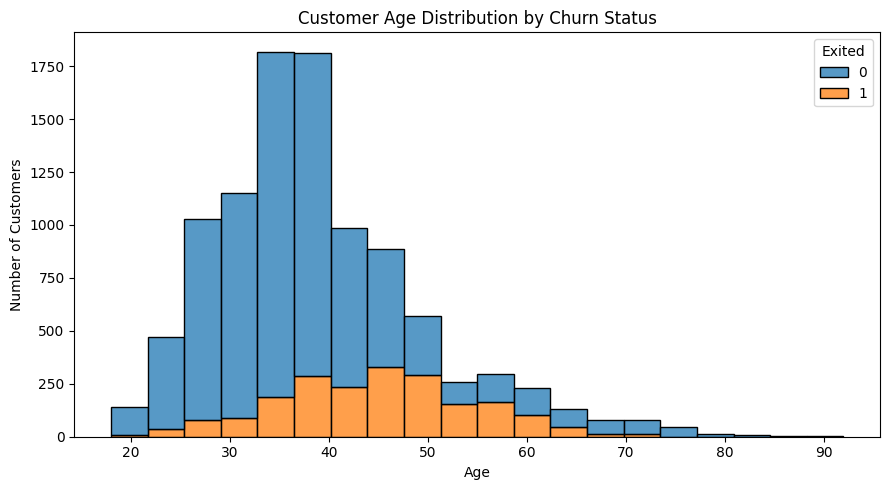

In [8]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=churn,
    x="Age",
    hue="Exited",
    bins=20,
    multiple="stack"
)

plt.title("Customer Age Distribution by Churn Status")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [9]:

age_analysis = (
    churn.groupby("Exited")["Age"]
    .agg(["mean", "median", "min", "max"])
)

age_analysis.index = ["Retained", "Churned"]

display(age_analysis.round(2))


,mean,median,min,max
Retained,37.41,36.0,18,92
Churned,44.84,45.0,18,84


,IsActiveMember,Churn Rate
0,Inactive,26.850897
1,Active,14.269074


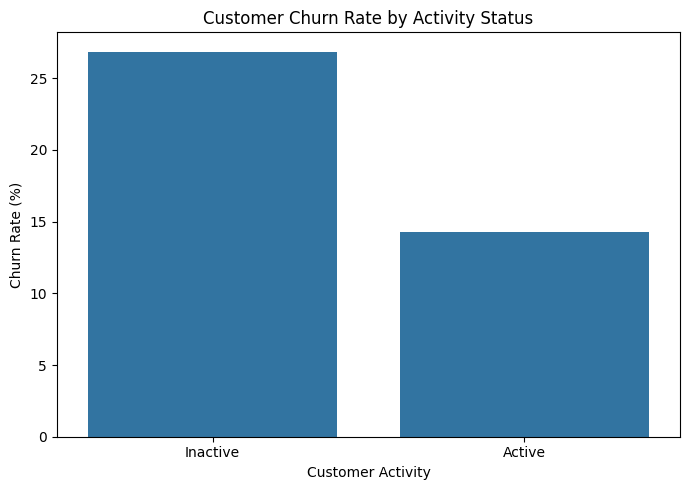

In [10]:

activity_churn = (
    churn.groupby("IsActiveMember")["Exited"]
    .mean()
    .mul(100)
    .reset_index(name="Churn Rate")
)

activity_churn["IsActiveMember"] = activity_churn[
    "IsActiveMember"
].map({0: "Inactive", 1: "Active"})

display(activity_churn)

plt.figure(figsize=(7, 5))
sns.barplot(
    data=activity_churn,
    x="IsActiveMember",
    y="Churn Rate"
)

plt.title("Customer Churn Rate by Activity Status")
plt.xlabel("Customer Activity")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


,NumOfProducts,count,Churn Rate
0,1,5084,27.71
1,2,4590,7.58
2,3,266,82.71
3,4,60,100.00


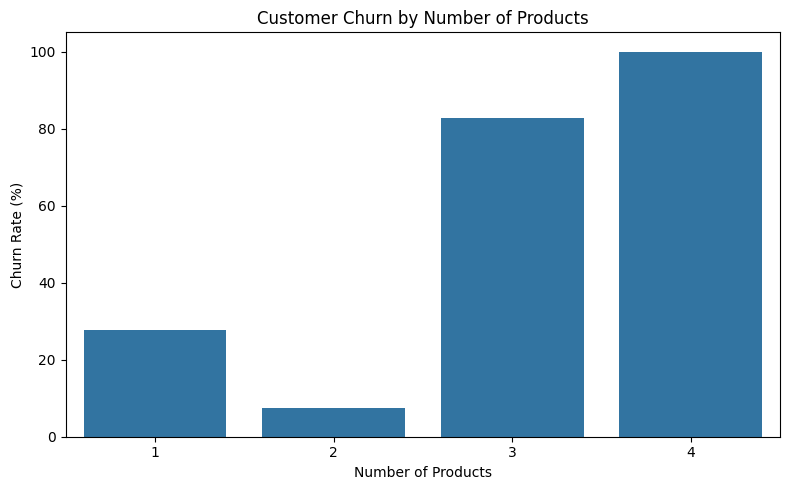

In [11]:

product_churn = (
    churn.groupby("NumOfProducts")["Exited"]
    .agg(["mean", "count"])
    .reset_index()
)

product_churn["Churn Rate"] = product_churn["mean"] * 100

display(
    product_churn[["NumOfProducts", "count", "Churn Rate"]].round(2)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=product_churn,
    x="NumOfProducts",
    y="Churn Rate"
)

plt.title("Customer Churn by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


,Balance Group,count,Churn Rate
0,Zero,3617,13.82
1,1-50K,75,34.67
2,50K-100K,1509,19.88
3,100K-150K,3830,25.77
4,Above 150K,969,23.12


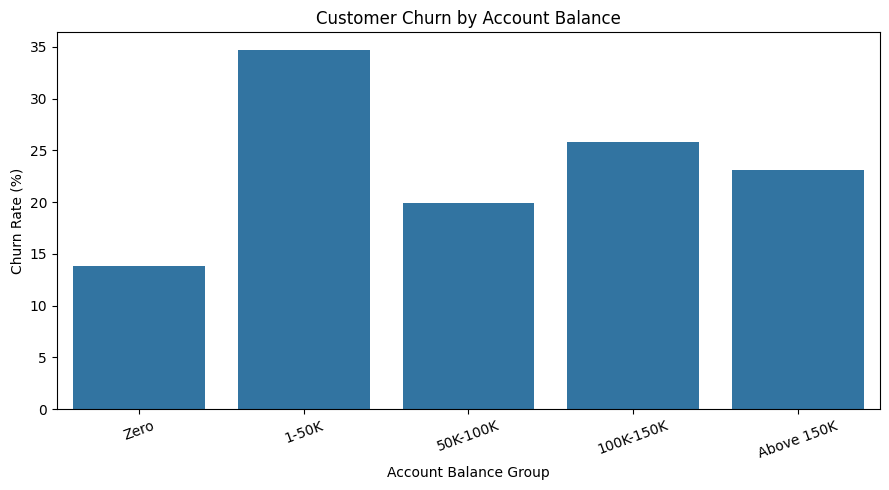

In [12]:

churn["Balance Group"] = pd.cut(
    churn["Balance"],
    bins=[-1, 0, 50000, 100000, 150000, float("inf")],
    labels=["Zero", "1-50K", "50K-100K", "100K-150K", "Above 150K"]
)

balance_churn = (
    churn.groupby("Balance Group", observed=False)["Exited"]
    .agg(["mean", "count"])
    .reset_index()
)

balance_churn["Churn Rate"] = balance_churn["mean"] * 100

display(
    balance_churn[["Balance Group", "count", "Churn Rate"]].round(2)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=balance_churn,
    x="Balance Group",
    y="Churn Rate"
)

plt.title("Customer Churn by Account Balance")
plt.xlabel("Account Balance Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [13]:

card_churn = (
    churn.groupby("HasCrCard")["Exited"]
    .agg(["mean", "count"])
    .reset_index()
)

card_churn["Card Ownership"] = card_churn["HasCrCard"].map({
    0: "No Credit Card",
    1: "Has Credit Card"
})

card_churn["Churn Rate"] = card_churn["mean"] * 100

display(
    card_churn[["Card Ownership", "count", "Churn Rate"]].round(2)
)


,Card Ownership,count,Churn Rate
0,No Credit Card,2945,20.81
1,Has Credit Card,7055,20.18


,NumOfProducts,Churn Rate
0,1,27.71
1,2,7.58
2,3,82.71
3,4,100.00


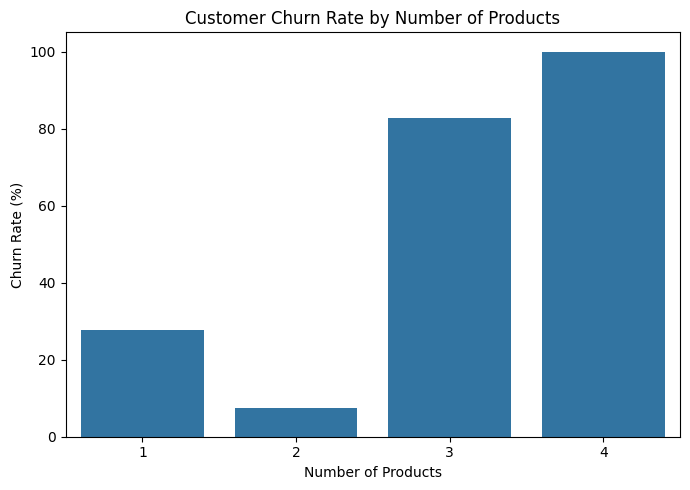

In [14]:

product_churn = (
    churn.groupby("NumOfProducts")["Exited"]
    .mean()
    .mul(100)
    .reset_index(name="Churn Rate")
)

display(product_churn.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(
    data=product_churn,
    x="NumOfProducts",
    y="Churn Rate"
)

plt.title("Customer Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


,Tenure,Churn Rate
0,0,23.00
1,1,22.42
2,2,19.18
3,3,21.11
4,4,20.53
5,5,20.65
6,6,20.27
7,7,17.22
8,8,19.22
9,9,21.65


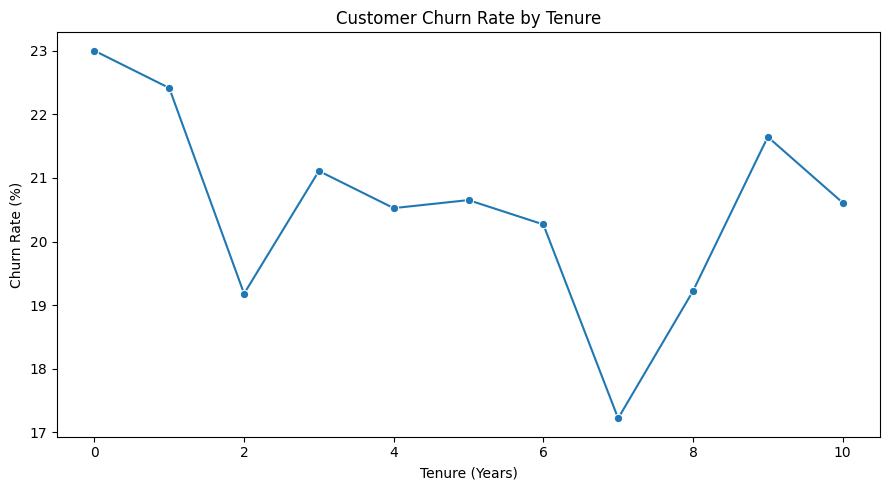

In [15]:

tenure_churn = (
    churn.groupby("Tenure")["Exited"]
    .mean()
    .mul(100)
    .reset_index(name="Churn Rate")
)

display(tenure_churn.round(2))

plt.figure(figsize=(9, 5))
sns.lineplot(
    data=tenure_churn,
    x="Tenure",
    y="Churn Rate",
    marker="o"
)

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Tenure (Years)")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


,HasCrCard,Churn Rate
0,No Credit Card,20.81
1,Has Credit Card,20.18


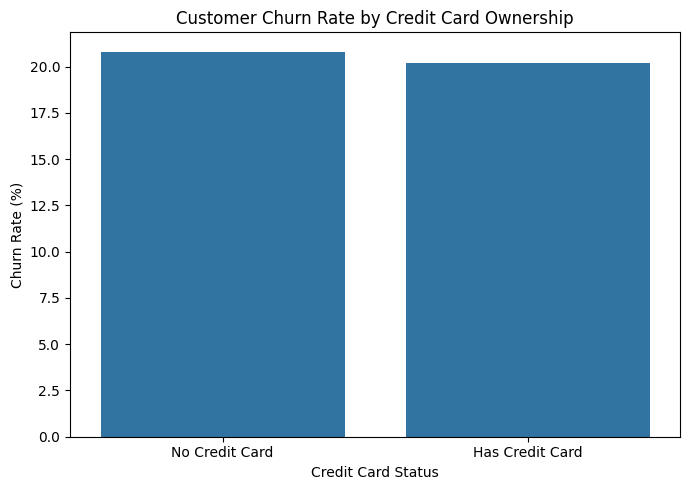

In [16]:

card_churn = (
    churn.groupby("HasCrCard")["Exited"]
    .mean()
    .mul(100)
    .reset_index(name="Churn Rate")
)

card_churn["HasCrCard"] = card_churn["HasCrCard"].map({
    0: "No Credit Card",
    1: "Has Credit Card"
})

display(card_churn.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(
    data=card_churn,
    x="HasCrCard",
    y="Churn Rate"
)

plt.title("Customer Churn Rate by Credit Card Ownership")
plt.xlabel("Credit Card Status")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


In [17]:

product_analysis = (
    churn.groupby("NumOfProducts")["Exited"]
    .agg(
        Total_Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

product_analysis["Churn_Rate"] = (
    product_analysis["Churn_Rate"] * 100
).round(2)

display(product_analysis)


,Total_Customers,Churned_Customers,Churn_Rate
NumOfProducts,,,
1,5084,1409,27.71
2,4590,348,7.58
3,266,220,82.71
4,60,60,100.00


Global Findex Analysis

In [18]:
pakistan_all = findex[
    (findex["countrynewwb"] == "Pakistan") &
    (findex["group"] == "all") &
    (findex["group2"] == "all")
].copy()

pakistan_all = pakistan_all.sort_values("year")

display(
    pakistan_all[
        [
            "year",
            "account_t_d",
            "fiaccount_t_d",
            "mobileaccount_t_d",
            "dig_acc"
        ]
    ]
)

,year,account_t_d,fiaccount_t_d,mobileaccount_t_d,dig_acc
5958,2011,0.103063,0.103063,NaN,NaN
5969,2014,0.130362,0.087061,0.057998,NaN
5980,2017,0.212932,0.180494,0.068856,NaN
5991,2021,0.209806,0.162882,0.085374,NaN
6002,2024,0.272960,0.182813,0.183579,0.198484


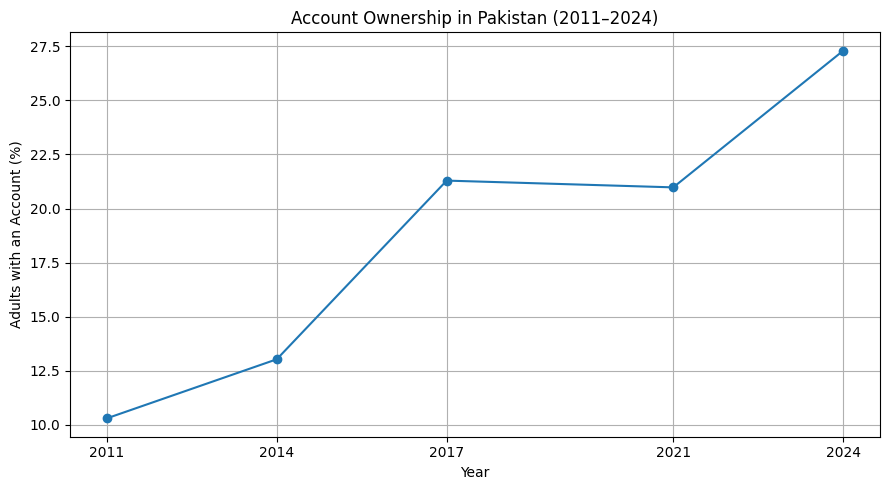

In [19]:
plt.figure(figsize=(9, 5))

plt.plot(
    pakistan_all["year"],
    pakistan_all["account_t_d"] * 100,
    marker="o"
)

plt.title("Account Ownership in Pakistan (2011–2024)")
plt.xlabel("Year")
plt.ylabel("Adults with an Account (%)")
plt.xticks(pakistan_all["year"])
plt.grid(True)
plt.tight_layout()
plt.show()

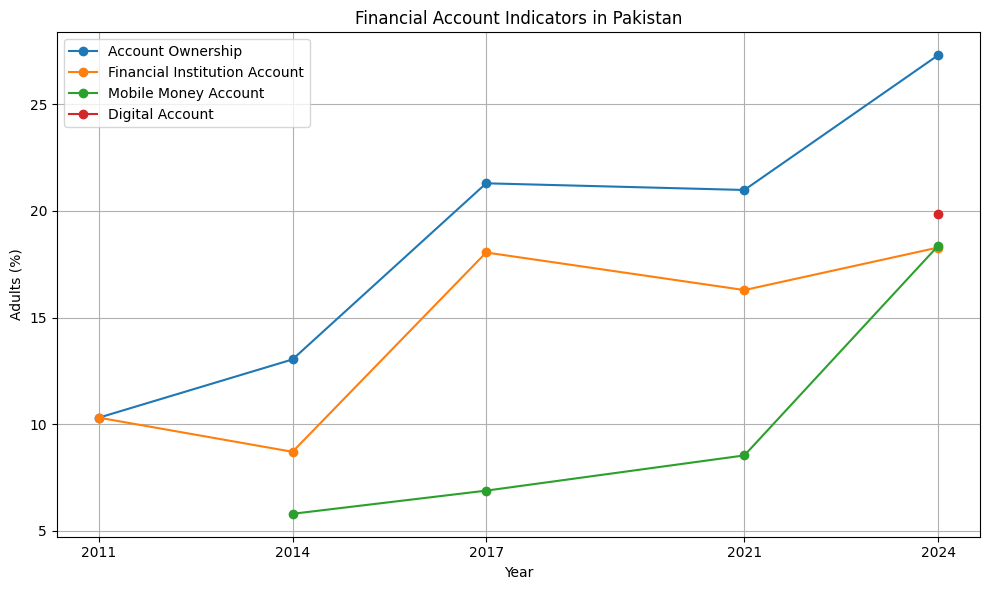

In [20]:
indicators = {
    "Account Ownership": "account_t_d",
    "Financial Institution Account": "fiaccount_t_d",
    "Mobile Money Account": "mobileaccount_t_d",
    "Digital Account": "dig_acc"
}

plt.figure(figsize=(10, 6))

for label, column in indicators.items():
    plt.plot(
        pakistan_all["year"],
        pakistan_all[column] * 100,
        marker="o",
        label=label
    )

plt.title("Financial Account Indicators in Pakistan")
plt.xlabel("Year")
plt.ylabel("Adults (%)")
plt.xticks(pakistan_all["year"])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
pakistan_2024 = findex[
    (findex["countrynewwb"] == "Pakistan") &
    (findex["year"] == 2024) &
    (findex["group"] != "all")
].copy()

display(
    pakistan_2024[
        [
            "group",
            "group2",
            "account_t_d",
            "fiaccount_t_d",
            "mobileaccount_t_d",
            "dig_acc"
        ]
    ]
)

,group,group2,account_t_d,fiaccount_t_d,mobileaccount_t_d,dig_acc
6000,age_cat,age 25+,0.285427,0.211594,0.182704,0.201544
6001,age_cat,ages 15-24,0.243425,0.114629,0.185651,0.191234
6003,education,prim edu or less,0.189107,0.117771,0.100075,0.108394
6004,education,secondary edu or more,0.466860,0.335103,0.376437,0.406753
6005,gender,men,0.422935,0.268150,0.321906,0.340751
6006,gender,women,0.119122,0.095277,0.041689,0.052552
6007,income,poorest 40%,0.136063,0.093021,0.074445,0.083094
6008,income,richest 60%,0.364062,0.242567,0.256204,0.275272
6009,laborforce,in laborforce,0.427340,0.287545,0.312512,0.331025
6010,laborforce,out of laborforce,0.139101,0.092001,0.071783,0.083560


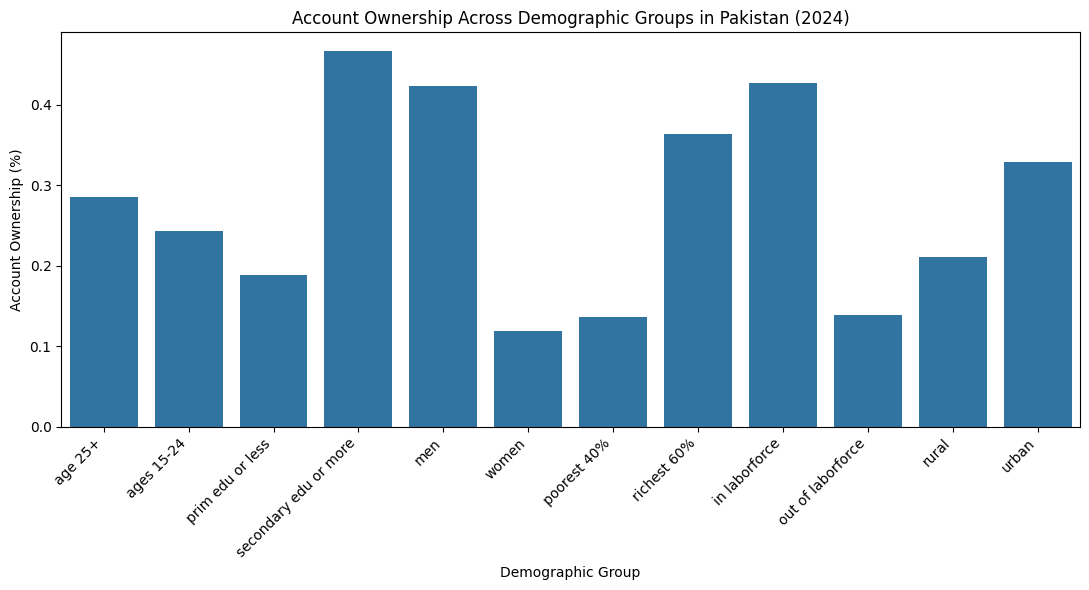

In [22]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=pakistan_2024,
    x="group2",
    y="account_t_d"
)

plt.title("Account Ownership Across Demographic Groups in Pakistan (2024)")
plt.xlabel("Demographic Group")
plt.ylabel("Account Ownership (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Active Mobile Money Accounts Analysis

In [24]:
print("Years covered:", mobile["Year"].min(), "-", mobile["Year"].max())

print("\nRegions:")
print(mobile["Entity"].unique())

print("\nRecords per region:")
display(mobile["Entity"].value_counts())

print("\nDataset summary:")
display(mobile.describe())

Years covered: 2010 - 2024

Regions:
['East Asia and Pacific' 'Europe and Central Asia'
 'Latin America and the Caribbean' 'Middle East and North Africa'
 'South Asia' 'Sub-Saharan Africa']

Records per region:


Entity
East Asia and Pacific              15
Europe and Central Asia            15
Latin America and the Caribbean    15
Middle East and North Africa       15
South Asia                         15
Sub-Saharan Africa                 15
Name: count, dtype: int64


Dataset summary:


,Year,Active mobile money accounts
count,90.000000,9.000000e+01
mean,2017.000000,5.099663e+07
std,4.344698,8.189549e+07
min,2010.000000,5.199104e+04
25%,2013.000000,4.163924e+06
50%,2017.000000,1.344793e+07
75%,2021.000000,7.073246e+07
max,2024.000000,4.300348e+08


In [25]:
mobile_growth = mobile.pivot(
    index="Entity",
    columns="Year",
    values="Active mobile money accounts"
)

growth_analysis = pd.DataFrame({
    "Accounts_2010": mobile_growth[2010],
    "Accounts_2024": mobile_growth[2024]
})

growth_analysis["Absolute_Growth"] = (
    growth_analysis["Accounts_2024"] -
    growth_analysis["Accounts_2010"]
)

growth_analysis["Percentage_Growth"] = (
    growth_analysis["Absolute_Growth"] /
    growth_analysis["Accounts_2010"]
) * 100

growth_analysis = growth_analysis.round(2)

display(growth_analysis.sort_values(
    "Percentage_Growth",
    ascending=False
))

,Accounts_2010,Accounts_2024,Absolute_Growth,Percentage_Growth
Entity,,,,
Latin America and the Caribbean,79433.22,30320092.0,3.024066e+07,38070.54
Middle East and North Africa,51991.04,19333152.0,1.928116e+07,37085.55
South Asia,957771.60,139414600.0,1.384568e+08,14456.14
East Asia and Pacific,1411639.00,149984820.0,1.485732e+08,10524.87
Europe and Central Asia,187530.45,11045833.0,1.085830e+07,5790.15
Sub-Saharan Africa,10431262.00,430034750.0,4.196035e+08,4022.56


In [26]:
south_asia = mobile[
    mobile["Entity"] == "South Asia"
].copy()

display(south_asia)

,Entity,Year,Active mobile money accounts
60,South Asia,2010,957771.6
61,South Asia,2011,1050089.0
62,South Asia,2012,2769991.8
63,South Asia,2013,11276791.0
64,South Asia,2014,21195138.0
65,South Asia,2015,36548012.0
66,South Asia,2016,56030144.0
67,South Asia,2017,71134120.0
68,South Asia,2018,87211100.0
69,South Asia,2019,82927000.0


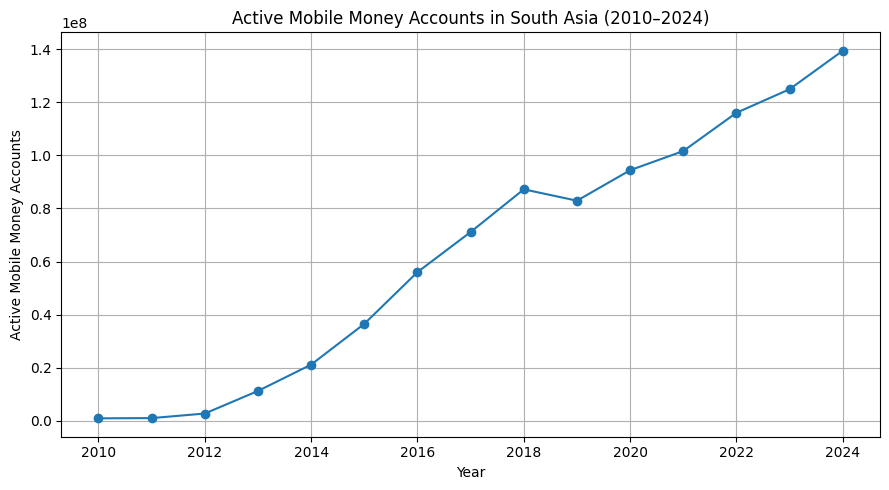

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    south_asia["Year"],
    south_asia["Active mobile money accounts"],
    marker="o"
)

plt.title("Active Mobile Money Accounts in South Asia (2010–2024)")
plt.xlabel("Year")
plt.ylabel("Active Mobile Money Accounts")
plt.grid(True)
plt.tight_layout()
plt.show()

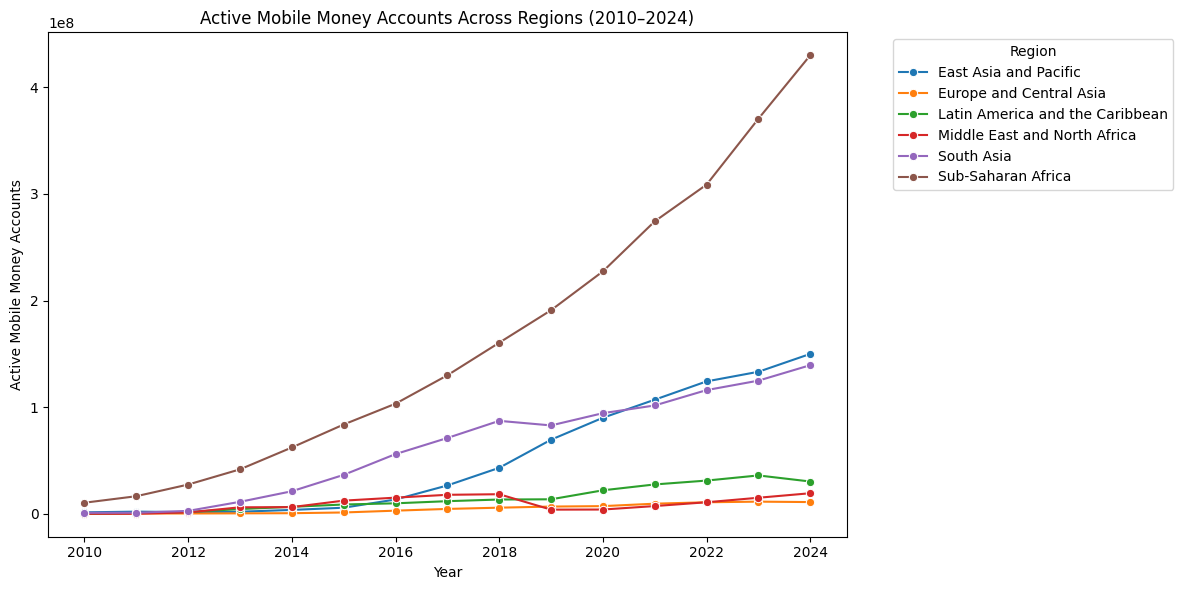

In [28]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=mobile,
    x="Year",
    y="Active mobile money accounts",
    hue="Entity",
    marker="o"
)

plt.title("Active Mobile Money Accounts Across Regions (2010–2024)")
plt.xlabel("Year")
plt.ylabel("Active Mobile Money Accounts")
plt.legend(title="Region", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [29]:
geo_summary = churn.groupby("Geography").agg(
    Total_Customers=("Exited", "count"),
    Churned_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
).reset_index()

geo_summary["Churn_Rate"] *= 100
geo_summary["Churn_Rate"] = geo_summary["Churn_Rate"].round(2)

display(geo_summary)

,Geography,Total_Customers,Churned_Customers,Churn_Rate
0,France,5014,810,16.15
1,Germany,2509,814,32.44
2,Spain,2477,413,16.67


In [30]:
gender_summary = churn.groupby("Gender").agg(
    Total_Customers=("Exited", "count"),
    Churned_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
).reset_index()

gender_summary["Churn_Rate"] *= 100
gender_summary["Churn_Rate"] = gender_summary["Churn_Rate"].round(2)

display(gender_summary)

,Gender,Total_Customers,Churned_Customers,Churn_Rate
0,Female,4543,1139,25.07
1,Male,5457,898,16.46


In [31]:
activity_summary = churn.groupby("IsActiveMember").agg(
    Total_Customers=("Exited", "count"),
    Churned_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
).reset_index()

activity_summary["Activity_Status"] = activity_summary[
    "IsActiveMember"
].map({0: "Inactive", 1: "Active"})

activity_summary["Churn_Rate"] *= 100
activity_summary["Churn_Rate"] = activity_summary["Churn_Rate"].round(2)

display(activity_summary)

,IsActiveMember,Total_Customers,Churned_Customers,Churn_Rate,Activity_Status
0,0,4849,1302,26.85,Inactive
1,1,5151,735,14.27,Active


In [32]:
churn["Age_Group"] = pd.cut(
    churn["Age"],
    bins=[17, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

age_summary = churn.groupby("Age_Group", observed=False).agg(
    Total_Customers=("Exited", "count"),
    Churned_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
).reset_index()

age_summary["Churn_Rate"] *= 100
age_summary["Churn_Rate"] = age_summary["Churn_Rate"].round(2)

display(age_summary)

,Age_Group,Total_Customers,Churned_Customers,Churn_Rate
0,18-25,611,46,7.53
1,26-35,3542,301,8.50
2,36-45,3736,733,19.62
3,46-55,1311,663,50.57
4,56+,800,294,36.75


In [33]:
geo_summary.to_csv(
    "../data/processed/churn_by_geography.csv",
    index=False
)

gender_summary.to_csv(
    "../data/processed/churn_by_gender.csv",
    index=False
)

activity_summary.to_csv(
    "../data/processed/churn_by_activity.csv",
    index=False
)

age_summary.to_csv(
    "../data/processed/churn_by_age_group.csv",
    index=False
)

print("Business insight tables saved successfully!")

Business insight tables saved successfully!


In [34]:
pakistan_trend = pakistan_all[
    [
        "year",
        "account_t_d",
        "fiaccount_t_d",
        "mobileaccount_t_d",
        "dig_acc"
    ]
].copy()

pakistan_trend.to_csv(
    "../data/processed/pakistan_findex_trend.csv",
    index=False
)

print("Pakistan Findex trend saved!")

Pakistan Findex trend saved!


In [35]:
pakistan_demographics = pakistan_2024[
    [
        "group",
        "group2",
        "account_t_d",
        "fiaccount_t_d",
        "mobileaccount_t_d",
        "dig_acc"
    ]
].copy()

pakistan_demographics.to_csv(
    "../data/processed/pakistan_findex_demographics_2024.csv",
    index=False
)

print("Pakistan demographic data saved!")

Pakistan demographic data saved!


In [36]:
mobile.to_csv(
    "../data/processed/mobile_money_region_year.csv",
    index=False
)

print("Mobile money regional data saved!")

Mobile money regional data saved!


In [37]:
growth_analysis.to_csv(
    "../data/processed/mobile_money_regional_growth.csv"
)

print("Mobile money growth data saved!")

Mobile money growth data saved!
